# Experimentos del módulo 3: recomendación de destinos

Este notebook sirve para **experimentar**: cambiar los hiperparámetros de los modelos y ver cómo cambian sus resultados, comparando todos los modelos con **el mismo evaluador y la misma partición** que el informe.

**Cómo usarlo**
1. Ejecuta las celdas en orden (*Run All* funciona).
2. Cambia los valores de la celda **«2. Hiperparámetros»** y vuelve a ejecutar desde ahí.
3. Las secciones 5 a 7 tienen experimentos listos: un barrido de un hiperparámetro, una curva de aprendizaje y las recomendaciones de un usuario.

**Dos reglas para experimentar con honestidad**
- Experimenta con `ESCENARIO = "ajuste"` (aprende con entrenamiento y mide en **validación**). El escenario `"final"` mide en **prueba** y en el informe se mira **una sola vez**: si eliges hiperparámetros mirando la prueba, sus resultados dejan de ser una evaluación justa.
- Con 326 usuarios en validación, diferencias de 1–3 puntos suelen ser **ruido**. Mira los p-valores y la desviación entre semillas antes de concluir (hallazgos 7 y «maldición del ganador» del informe).

Los modelos y el evaluador están en `modulo3_recomendacion/src/` (`experimentos.py`, `evaluacion.py`, `dos_torres.py`, `factorizacion.py`, `referencias.py`).

## 1. Preparación

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Busca la carpeta src/ del módulo 3 tanto si el notebook se abre desde notebooks/ como desde la raíz del repo
for base in (Path.cwd(), *Path.cwd().parents):
    src = base / "src" if (base / "src" / "evaluacion.py").exists() else base / "modulo3_recomendacion" / "src"
    if (src / "evaluacion.py").exists():
        sys.path.insert(0, str(src))
        break
else:
    raise FileNotFoundError("No encuentro modulo3_recomendacion/src")

import experimentos as ex

pd.set_option("display.max_columns", 30, "display.width", 200)
print("Usando el código de:", src)

Usando el código de: /home/mgtdev/documentos_estudio/ESTADISTICA/TAREAS_REDES_NEURONALES/T03/modulo3_recomendacion/src


## 2. Hiperparámetros

Cada modelo se define con un **nombre** (el que verás en las tablas), su **tipo** y sus **hiperparámetros**. Puedes:
- cambiar cualquier valor;
- comentar un modelo para no correrlo;
- **agregar variantes** del mismo tipo con otro nombre (por ejemplo, dos redes con distinta `d`) para compararlas lado a lado.

| Tipo | Hiperparámetros |
|---|---|
| `Azar`, `Popularidad` | ninguno |
| `Factorización` | `d` (dimensión), `lam` (regularización λ), `epocas`, `lr` (tasa de aprendizaje), `lote` |
| `Red` | `d`, `perdida` (`"bce"` o `"bpr"`), `negativos` (por positivo), `usuario` (`"preferencias"` o `"completo"`), `epocas`, `lr`, `decaimiento` (pesos), `oculta` (neuronas), `lote` |

Los valores de partida son los que se eligieron en el informe (secciones 6.4 y 7.4).

In [2]:
ESCENARIO = "ajuste"   # "ajuste" → mide en validación (experimentar) · "final" → mide en prueba (solo al final)
SEMILLAS = 3           # repeticiones con semillas distintas (el informe usa 30 en el escenario final)

MODELOS = {
    "Azar":          {"tipo": "Azar"},
    "Popularidad":   {"tipo": "Popularidad"},
    "Factorización": {"tipo": "Factorización", "hp": {"d": 8, "lam": 1.0, "epocas": 7, "lr": 0.01}},
    "Red":           {"tipo": "Red", "hp": {"d": 2, "perdida": "bce", "negativos": 1, "usuario": "preferencias",
                                            "epocas": 8, "lr": 0.01, "decaimiento": 1e-4, "oculta": 16}},
    # Ejemplo de variante: descomenta para comparar
    # "Red d=8 BPR":   {"tipo": "Red", "hp": {"d": 8, "perdida": "bpr", "negativos": 4, "usuario": "preferencias", "epocas": 8}},
}

## 3. Entrenar y evaluar

In [3]:
por_semilla, por_usuario = ex.entrenar_y_evaluar(MODELOS, ESCENARIO, SEMILLAS)

✓ Azar: 3 semilla(s)


✓ Popularidad: 3 semilla(s)


✓ Factorización: 3 semilla(s)


✓ Red: 3 semilla(s)


## 4. Comparación de todos los modelos

**Cómo leer la tabla**
- **HitRate, Recall, Precision, NDCG @10** (por ID): ¿quedó el destino escondido exacto entre los 10 primeros de 1000? El azar da ≈ 1 % de HitRate.
- **Lugar@3** (métrica principal) y **Lugar@1**: ¿quedó el *lugar* escondido entre los 3 que ve el cliente, o primero? El azar da 60 % y 20 %.
- **Cobertura@10**: % de los 1000 destinos que aparece en algún top-10.
- **p-valor vs azar**: prueba binomial unilateral (H₀: acierta como el azar; H₁: acierta más). Menor que 0,05 → hay evidencia de que supera al azar. No están corregidos por pruebas múltiples: si comparas muchas variantes, alguna saldrá baja por suerte.
- **±**: desviación entre semillas (solo mide el azar del entrenamiento, no el de la muestra de usuarios).

In [4]:
ex.tabla_comparativa(por_semilla, por_usuario)

,modelo,HitRate@10 (%),NDCG@10 (%),Precision@10 (%),Recall@10 (%),Cobertura@10 (%),Lugar@3 (%),Lugar@1 (%),p-valor Lugar@3 vs azar,p-valor HitRate@10 vs azar,parámetros,segundos por entrenamiento
0,Azar,0.72 ± 0.47,0.27,0.072,0.72,95.9,62.4,20.4,0.218,0.839,0,0.00
1,Popularidad,0.92 ± 0.61,0.30,0.092,0.92,1.8,62.4,22.0,0.218,0.635,0,0.00
2,Factorización,1.64 ± 0.47,0.67,0.164,1.64,18.4,58.6,20.6,0.719,0.230,15992,0.29
3,Red,1.94 ± 0.77,0.96,0.194,1.94,2.6,63.2,21.3,0.131,0.112,238,0.10


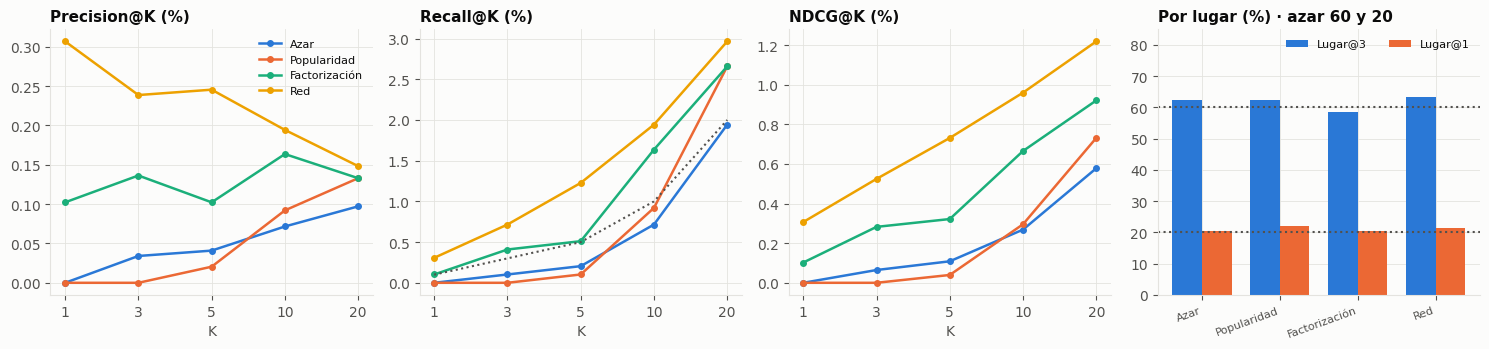

In [5]:
fig = ex.grafico_metricas_k(por_semilla)

### Comparar dos modelos en los mismos usuarios

La tabla compara cada modelo con el azar. Para saber si un modelo es mejor que **otro**, hay que compararlos en los **mismos usuarios** (prueba pareada de permutación de signos). Cambia los nombres por los de tu diccionario `MODELOS`.

In [6]:
pd.DataFrame([
    ex.comparar_pareado(por_usuario, "Red", "Popularidad", "Lugar@3"),
    ex.comparar_pareado(por_usuario, "Red", "Factorización", "Lugar@3"),
])

,comparación,métrica,diferencia (puntos),p-valor (pareada)
0,Red − Popularidad,Lugar@3,0.82,0.829
1,Red − Factorización,Lugar@3,4.60,0.068


## 5. Barrido de un hiperparámetro

Cambia **un** hiperparámetro manteniendo los demás fijos y mira cómo responde la métrica. Las barras son la desviación entre semillas. Ejemplos para probar:
- `ex.barrido("Red", MODELOS["Red"]["hp"], "d", [2, 4, 8, 16])`
- `ex.barrido("Factorización", MODELOS["Factorización"]["hp"], "lam", [0.01, 0.1, 1.0], metrica="NDCG")`
- `ex.barrido("Red", MODELOS["Red"]["hp"], "negativos", [1, 4, 8])`

✓ d=2: 3 semilla(s)


✓ d=4: 3 semilla(s)


✓ d=8: 3 semilla(s)


,modelo,d,HitRate_lugar@3 media (%),desviación entre semillas
0,d=2,2,63.19,2.96
1,d=4,4,61.66,3.73
2,d=8,8,59.61,3.88


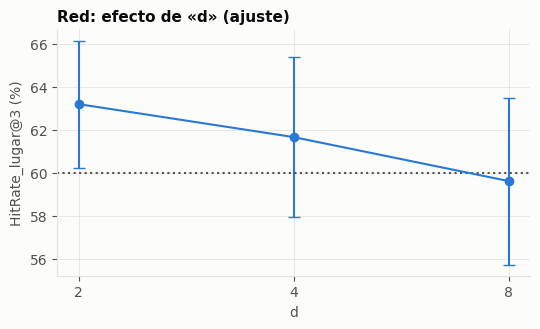

In [7]:
tabla_barrido, fig = ex.barrido("Red", MODELOS["Red"]["hp"], "d", [2, 4, 8], escenario=ESCENARIO, semillas=SEMILLAS)
tabla_barrido

## 6. Curva de aprendizaje

Entrena midiendo en validación después de cada época, sin parar antes, para ver cómo evolucionan la pérdida y la métrica. Si la pérdida baja pero la métrica de validación no sube, el modelo está memorizando o no hay nada que aprender.

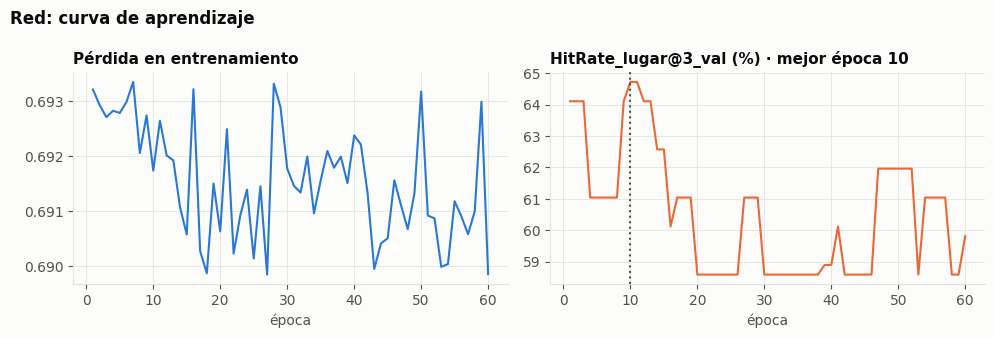

In [8]:
historia, fig = ex.curva_aprendizaje("Red", {**MODELOS["Red"]["hp"], "epocas": 60})

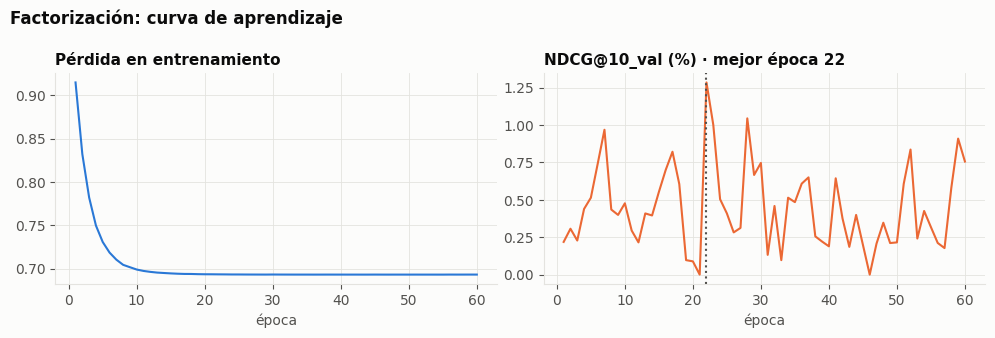

In [9]:
historia_fm, fig = ex.curva_aprendizaje("Factorización", {**MODELOS["Factorización"]["hp"], "epocas": 60})

## 7. ¿Qué le recomienda cada modelo a un usuario?

Cambia `USUARIO` (1 a 999). Se entrena cada modelo una vez con entrenamiento + validación y se muestran sus 3 lugares.

In [10]:
USUARIO = 1
tabla_usuario, info = ex.recomendaciones_de(USUARIO, MODELOS)
print(info)
tabla_usuario

{'historial (lo aprendido)': 'Goa Beaches', 'lugar escondido': 'Taj Mahal'}


,modelo,recomienda (3 lugares)
0,Azar,"Taj Mahal, Kerala Backwaters, Jaipur City"
1,Popularidad,"Jaipur City, Goa Beaches, Kerala Backwaters"
2,Factorización,"Taj Mahal, Jaipur City, Leh Ladakh"
3,Red,"Goa Beaches, Taj Mahal, Jaipur City"
